In [3]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
# Load Iris dataset
iris = load_iris()

# Display dataset information
print("Dataset loaded successfully!")
print("Feature Names:", iris.feature_names)
print("Target Names:", iris.target_names)
print("Dataset Shape:", iris.data.shape)

Dataset loaded successfully!
Feature Names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target Names: ['setosa' 'versicolor' 'virginica']
Dataset Shape: (150, 4)


In [5]:
# Display first 5 rows of the dataset
print("First 5 rows of Iris Dataset:")

print(iris.data[:5])

First 5 rows of Iris Dataset:
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]


In [6]:
# Display target values
print("Target Values:")
print(iris.target)

print("\nFlower Species:")
print(iris.target_names)

Target Values:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]

Flower Species:
['setosa' 'versicolor' 'virginica']


In [7]:
# Input features
X = iris.data

# Target variable
y = iris.target

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features Shape: (150, 4)
Target Shape: (150,)


In [8]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (120, 4)
Testing Data: (30, 4)


In [9]:
# Create StandardScaler
scaler = StandardScaler()

# Fit and transform training data
X_train = scaler.fit_transform(X_train)

# Transform testing data
X_test = scaler.transform(X_test)

print("Feature Scaling Completed Successfully!")
print("Scaled Training Data:")
print(X_train[:5])

Feature Scaling Completed Successfully!
Scaled Training Data:
[[-1.47393679  1.20365799 -1.56253475 -1.31260282]
 [-0.13307079  2.99237573 -1.27600637 -1.04563275]
 [ 1.08589829  0.08570939  0.38585821  0.28921757]
 [-1.23014297  0.75647855 -1.2187007  -1.31260282]
 [-1.7177306   0.30929911 -1.39061772 -1.31260282]]


In [10]:
# Create KNN classifier
model = KNeighborsClassifier(n_neighbors=3)

# Train the model
model.fit(X_train, y_train)

print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [11]:
# Predict flower species
y_pred = model.predict(X_test)

print("Predicted Values:")
print(y_pred)

print("\nActual Values:")
print(y_test)

Predicted Values:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]

Actual Values:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]


In [12]:
# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 100.0 %


In [13]:
# Generate classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [14]:
# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


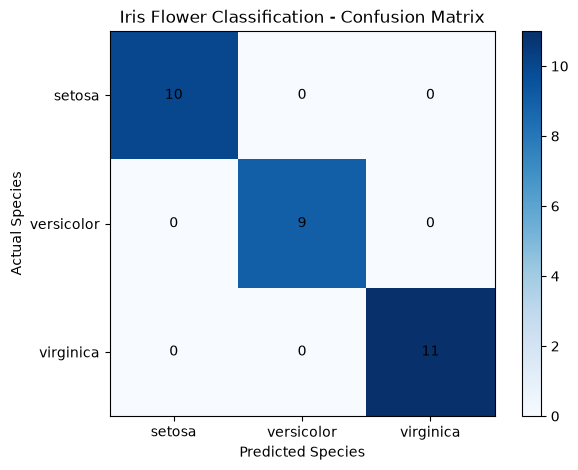

In [18]:
# Confusion Matrix Visualization using Matplotlib

plt.figure(figsize=(7, 5))

plt.imshow(cm, cmap='Blues')
plt.colorbar()

plt.xticks(range(3), iris.target_names)
plt.yticks(range(3), iris.target_names)

for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Iris Flower Classification - Confusion Matrix")

plt.show()

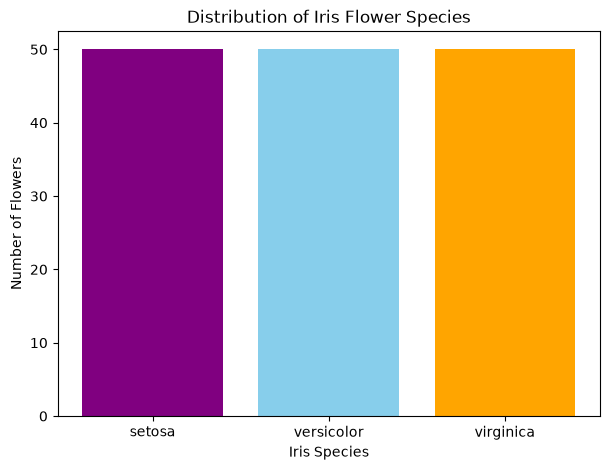

In [19]:
# Count flowers in each species
unique, counts = np.unique(y, return_counts=True)

plt.figure(figsize=(7, 5))

plt.bar(
    iris.target_names,
    counts,
    color=['purple', 'skyblue', 'orange']
)

plt.xlabel("Iris Species")
plt.ylabel("Number of Flowers")
plt.title("Distribution of Iris Flower Species")

plt.show()

In [20]:
# New flower measurements
new_flower = [[5.1, 3.5, 1.4, 0.2]]

# Scale the new data
new_flower_scaled = scaler.transform(new_flower)

# Predict species
prediction = model.predict(new_flower_scaled)

print("Predicted Flower Species:",
      iris.target_names[prediction[0]])

Predicted Flower Species: setosa


In [21]:
print("IRIS FLOWER CLASSIFICATION PROJECT")
print("-----------------------------------")

print("Algorithm: K-Nearest Neighbors (KNN)")
print("Dataset: Iris Dataset")
print("Total Samples:", len(iris.data))
print("Total Features:", len(iris.feature_names))
print("Total Classes:", len(iris.target_names))

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nProject Completed Successfully!")

IRIS FLOWER CLASSIFICATION PROJECT
-----------------------------------
Algorithm: K-Nearest Neighbors (KNN)
Dataset: Iris Dataset
Total Samples: 150
Total Features: 4
Total Classes: 3
Model Accuracy: 100.0 %

Project Completed Successfully!
